### IPD440 - APRENDIZAJE DE MAQUINAS
# Clase 12: Sequence to Sequence Learning
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Neurona recurrente

<div align="center">
    <img src="img/rnn.png" alt="" width="80%" align="center" />
</div>

# Capas recurrentes

- SimpleRNN layer
- LSTM layer
- GRU layer
- Bidirectional layer
- etc.


### Capa Recurrente

Una capa **Recurrente** (`SimpleRNN`) es una Fully-connected RNN donde la salida en tiempo $t$, se usa para alimentar la entrada en tiempo $t+1$.

<div align="center">
    <img src="img/rnn-vs-fnn.png" alt="" width="50%" align="center" />
</div>

In [1]:
import pandas as pd
import numpy as np
from keras.models import Sequential
from keras.layers import Dense, SimpleRNN
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import math
import matplotlib.pyplot as plt

In [2]:
# Parameter split_percent defines the ratio of training examples
def get_train_test(url, split_percent=0.8):
    df = pd.read_csv(url, usecols=[1], engine='python')
    data = np.array(df.values.astype('float32'))
    scaler = MinMaxScaler(feature_range=(0, 1))
    data = scaler.fit_transform(data).flatten()
    n = len(data)
    # Point for splitting data into train and test
    split = int(n*split_percent)
    train_data = data[range(split)]
    test_data = data[split:]
    return train_data, test_data, data

In [3]:
# Prepare the input X and target Y
def get_XY(dat, time_steps):
    Y_ind = np.arange(time_steps, len(dat), time_steps)
    Y = dat[Y_ind]
    rows_x = len(Y)
    X = dat[range(time_steps*rows_x)]
    X = np.reshape(X, (rows_x, time_steps, 1))    
    return X, Y

In [4]:
def print_error(trainY, testY, train_predict, test_predict):    
    # Error of predictions
    train_rmse = math.sqrt(mean_squared_error(trainY, train_predict))
    test_rmse = math.sqrt(mean_squared_error(testY, test_predict))
    # Print RMSE
    print('Train RMSE: %.3f RMSE' % (train_rmse))
    print('Test RMSE: %.3f RMSE' % (test_rmse)) 

In [5]:
# Plot the result
def plot_result(trainY, testY, train_predict, test_predict):
    actual = np.append(trainY, testY)
    predictions = np.append(train_predict, test_predict)
    rows = len(actual)
    plt.figure(figsize=(15, 6), dpi=80)
    plt.plot(range(rows), actual)
    plt.plot(range(rows), predictions)
    plt.axvline(x=len(trainY), color='r')
    plt.legend(['Actual', 'Predictions'])
    plt.xlabel('Observation number after given time steps')
    plt.ylabel('Sunspots scaled')
    plt.title('Actual and Predicted Values. The Red Line Separates The Training And Test Examples')

In [6]:
time_steps = 12
train_data, test_data, data = get_train_test('sunspots.csv')
trainX, trainY = get_XY(train_data, time_steps)
testX, testY = get_XY(test_data, time_steps)

In [7]:
model = Sequential()
model.add(SimpleRNN(3, input_shape=(time_steps,1), activation='tanh'))
model.add(Dense(units=1, activation='tanh'))

In [8]:
model.compile(loss='mean_squared_error', optimizer='adam')

In [9]:
model.fit(trainX, trainY, epochs=20, batch_size=1, verbose=2)

Epoch 1/20
187/187 - 1s - loss: 0.2284 - 1s/epoch - 6ms/step
Epoch 2/20
187/187 - 0s - loss: 0.1074 - 296ms/epoch - 2ms/step
Epoch 3/20
187/187 - 0s - loss: 0.0766 - 284ms/epoch - 2ms/step
Epoch 4/20
187/187 - 0s - loss: 0.0606 - 299ms/epoch - 2ms/step
Epoch 5/20
187/187 - 0s - loss: 0.0503 - 301ms/epoch - 2ms/step
Epoch 6/20
187/187 - 0s - loss: 0.0433 - 300ms/epoch - 2ms/step
Epoch 7/20
187/187 - 0s - loss: 0.0385 - 317ms/epoch - 2ms/step
Epoch 8/20
187/187 - 0s - loss: 0.0341 - 312ms/epoch - 2ms/step
Epoch 9/20
187/187 - 0s - loss: 0.0302 - 321ms/epoch - 2ms/step
Epoch 10/20
187/187 - 0s - loss: 0.0270 - 337ms/epoch - 2ms/step
Epoch 11/20
187/187 - 0s - loss: 0.0252 - 300ms/epoch - 2ms/step
Epoch 12/20
187/187 - 0s - loss: 0.0231 - 324ms/epoch - 2ms/step
Epoch 13/20
187/187 - 0s - loss: 0.0214 - 305ms/epoch - 2ms/step
Epoch 14/20
187/187 - 0s - loss: 0.0198 - 310ms/epoch - 2ms/step
Epoch 15/20
187/187 - 0s - loss: 0.0189 - 306ms/epoch - 2ms/step
Epoch 16/20
187/187 - 0s - loss: 0.01

In [10]:
# make predictions
train_predict = model.predict(trainX)
test_predict = model.predict(testX)

2/2 [==============================] - 0s 2ms/step


In [11]:
# Print error
print_error(trainY, testY, train_predict, test_predict)

Train RMSE: 0.127 RMSE
Test RMSE: 0.161 RMSE


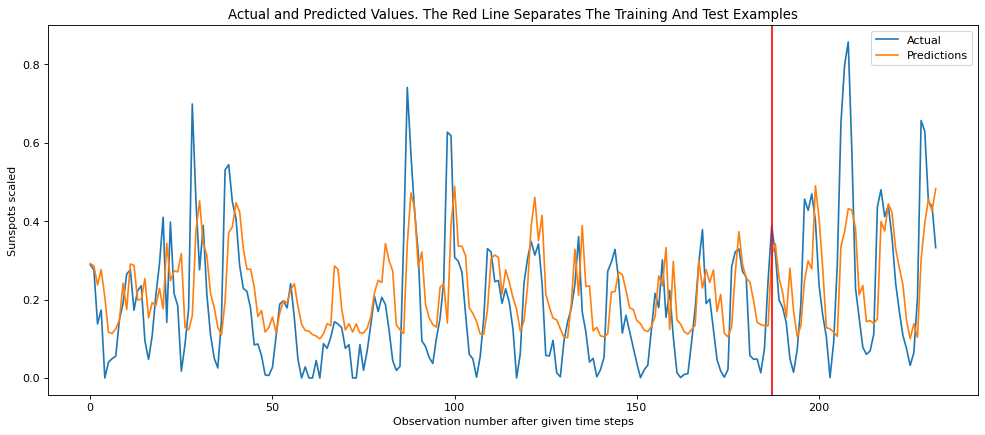

In [12]:
#Plot result
plot_result(trainY, testY, train_predict, test_predict)

# El problema de las dependencias a largo plazo

Las RNNs sufren de memoria a corto plazo y van olvidando las primeras entradas de la secuencia. 

<pre>
... and that's why now I speak fluent _____. 
</pre>

Para mitigar este problema, se crearon dos redes neuronales recurrentes especializadas: Long Short-Term Memory (LSTM) y Gated Recurrent Units (GRU). Ambas son capaces de aprender secuencias a largo plazo, utilizando compuertas lógicas que realizan diferentes operaciones tensoriales, permitiendo aprender qué información mantener y qué información eliminar en la capa oculta.

### Long Short-Term Memory

En una LSTM, cada neurona mantiene un estado de memoria de la celda $c_t$ en el tiempo $t$ y tiene tres compuertas: de olvido, de entrada y de salida.

<div align="center">
    <img src="img/LSTM.png" alt="" width="50%" align="center" />
</div>

# El problema del contexto pasado y futuro
<pre>
Apple is my favorite _____. (fruit/company/phone)
</pre>

<pre>
Apple is my favourite _____, and I work there.
Apple is my favorite _____, and I am going to buy one.
</pre>

###  Bidirectional recurrent neural networks (BRNN)

Procesan secuencias hacia adelante y hacia atrás (o de izquierda a derecha y viceversa).

<div align="center">
    <img src="img/rnn-vs-brnn.jpeg" alt="" width="60%" align="center" />
</div>

Las Bi-RNN (b) consisten en dos RNN (a) separadas que procesan los datos de entrada en direcciones opuestas, y las salidas de estas RNN se combinan para producir la salida final.

# Sequence to Sequence (Seq2Seq) Model

<div align="center">
    <img src="img/seq2seq.png" alt="" width="60%" align="center" />
</div>

In [13]:
batch_size = 128  # Batch size for training.
epochs = 30  # Epochs for training
latent_dim = 256  # Encoder-Decoder latent dimensions

In [14]:
all_chars = '0123456789+'

In [15]:
num_features = len(all_chars)

char_to_index = dict((c, i) for i, c in enumerate(all_chars))
index_to_char = dict((i, c) for i, c in enumerate(all_chars))

In [16]:
def generate_data(num_examples=2000,low=0,high=100):
    input_texts = []
    target_texts = []
    for i in range(num_examples):
        first_num = np.random.randint(low,high)
        second_num = np.random.randint(low,high)
        example = str(first_num) + '+' + str(second_num)
        input_texts.append(example)
        label = str(first_num+second_num)
        target_texts.append('_' + label + '_')
    return input_texts,target_texts

In [17]:
input_texts,target_texts = generate_data(10000)

In [18]:
print(input_texts[:5])
print(target_texts[:5])
print('Data Size:', len(input_texts))

['89+46', '51+63', '25+60', '32+12', '11+57']
['_135_', '_114_', '_85_', '_44_', '_68_']
Data Size: 10000


Train-Test Split

In [19]:
from random import randint

inds = np.arange(len(input_texts))
np.random.shuffle(inds)

train_test_ratio = 0.9
train_size = int(round(len(input_texts) * train_test_ratio))
train_inds = inds[:train_size]
test_inds = inds[train_size:]

tr_input_texts = [input_texts[ti] for ti in train_inds]
tr_target_texts = [target_texts[ti] for ti in train_inds]

ts_input_texts = [input_texts[ti] for ti in test_inds]
ts_target_texts = [target_texts[ti] for ti in test_inds]

In [20]:
print('Number of Samples:', len(input_texts))
print('Number of Samples in Training:', len(tr_input_texts))
print('Number of Samples in Testing:', len(ts_input_texts))

Number of Samples: 10000
Number of Samples in Training: 9000
Number of Samples in Testing: 1000


Text to Sequences

In [21]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [22]:
input_tokenizer = Tokenizer(char_level=True)
input_tokenizer.fit_on_texts(tr_input_texts)
encoder_input_sequences = input_tokenizer.texts_to_sequences(tr_input_texts)
input_maxlen = np.max([len(l) for l in encoder_input_sequences])
encoder_input_sequences = pad_sequences(encoder_input_sequences,
                                        padding='post',
                                        maxlen=input_maxlen)

target_tokenizer = Tokenizer(char_level=True)
target_tokenizer.fit_on_texts(tr_target_texts)
target_sequences = target_tokenizer.texts_to_sequences(tr_target_texts)
target_maxlen = np.max([len(l) for l in target_sequences])
target_sequences = pad_sequences(target_sequences,
                                 padding='post',
                                 maxlen=target_maxlen)

In [23]:
# ### vocab size
input_vsize = max(input_tokenizer.index_word.keys()) + 1
target_vsize = max(target_tokenizer.index_word.keys()) + 1

In [24]:
print(tr_input_texts[:3])
print(encoder_input_sequences[:3])

['15+17', '43+40', '5+98']
[[ 3  7  1  3  4]
 [ 9 10  1  9 11]
 [ 7  1  8  5  0]]


In [25]:
print(input_tokenizer.word_index)

{'+': 1, '6': 2, '1': 3, '7': 4, '8': 5, '2': 6, '5': 7, '9': 8, '4': 9, '3': 10, '0': 11}


In [26]:
print(tr_target_texts[:3])
print(target_sequences[:3])

['_32_', '_83_', '_103_']
[[ 1  3  6  1  0]
 [ 1  4  3  1  0]
 [ 1  2 11  3  1]]


In [27]:
print(target_tokenizer.word_index)

{'_': 1, '1': 2, '3': 3, '8': 4, '5': 5, '2': 6, '7': 7, '9': 8, '4': 9, '6': 10, '0': 11}


En la etapa de entrenamiento, le damos al Decoder las secuencias objetivo correctas con una diferencia de paso de tiempo (es decir, la salida del decodificador en $t-1$ es la entrada del decodificador en $t$).

In [28]:
decoder_input_sequences = target_sequences[:,:-1]
decoder_output_sequences = target_sequences[:,1:]
print(decoder_input_sequences[:5])
print(decoder_output_sequences[:5])

[[ 1  3  6  1]
 [ 1  4  3  1]
 [ 1  2 11  3]
 [ 1  8 10  1]
 [ 1  7  4  1]]
[[ 3  6  1  0]
 [ 4  3  1  0]
 [ 2 11  3  1]
 [ 8 10  1  0]
 [ 7  4  1  0]]


Secuencias para codificación One-Hot

In [29]:
from tensorflow.keras.utils import to_categorical

In [30]:
encoder_input_onehot = to_categorical(encoder_input_sequences,
                                      num_classes=input_vsize)
decoder_input_onehot = to_categorical(decoder_input_sequences,
                                      num_classes=target_vsize)
decoder_output_onehot = to_categorical(decoder_output_sequences,
                                       num_classes=target_vsize)

Token Indices

In [31]:
""" Index2word """
enc_index2word = dict(
    zip(input_tokenizer.word_index.values(),
        input_tokenizer.word_index.keys()))
dec_index2word = dict(
    zip(target_tokenizer.word_index.values(),
        target_tokenizer.word_index.keys()))

In [32]:
enc_index2word[0] = ''
dec_index2word[0] = ''

In [33]:
print(enc_index2word)

{1: '+', 2: '6', 3: '1', 4: '7', 5: '8', 6: '2', 7: '5', 8: '9', 9: '4', 10: '3', 11: '0', 0: ''}


In [34]:
print(dec_index2word)

{1: '_', 2: '1', 3: '3', 4: '8', 5: '5', 6: '2', 7: '7', 8: '9', 9: '4', 10: '6', 11: '0', 0: ''}


## Model 1 (Vanilla RNN)

<div align="center">
    <img src="img/seq2seq-vanilla-rnn.jpeg" alt="" width="50%" align="center" />
</div>

In [35]:
from tensorflow.keras.layers import Input
from tensorflow.keras.layers import TimeDistributed
from tensorflow.keras import Model

In [36]:
# Define Model Inputs
encoder_inputs = Input(shape=(input_maxlen, input_vsize),
                       name='encoder_inputs')
decoder_inputs = Input(shape=(target_maxlen - 1, target_vsize),
                       name='decoder_inputs')

# Encoder RNN
    ## first return is the hidden states of all timesteps of encoder
    ## second return is the last hidden state of encoder
encoder_rnn = SimpleRNN(latent_dim,
                        return_sequences=True,
                        return_state=True,
                        name='encoder_rnn')
_, encoder_state = encoder_rnn(encoder_inputs)


# Decoder RNN
    ## using `encoder_state` (last h) as initial state.
    ## using `decoder_inputs` for teacher forcing learning
decoder_rnn = SimpleRNN(latent_dim,
                        return_sequences=True,
                        return_state=True,
                        name='decoder_rnn')
decoder_out, _ = decoder_rnn(decoder_inputs, initial_state=encoder_state)

# Dense layer
dense = Dense(target_vsize, activation='softmax', name='softmax_layer')
dense_time = TimeDistributed(dense, name='time_distributed_layer')
decoder_pred = dense_time(decoder_out)

# Full model
full_model1 = Model(inputs=[encoder_inputs, decoder_inputs],
                    outputs=decoder_pred)

In [37]:
full_model1.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 encoder_inputs (InputLayer)    [(None, 5, 12)]      0           []                               
                                                                                                  
 decoder_inputs (InputLayer)    [(None, 4, 12)]      0           []                               
                                                                                                  
 encoder_rnn (SimpleRNN)        [(None, 5, 256),     68864       ['encoder_inputs[0][0]']         
                                 (None, 256)]                                                     
                                                                                                  
 decoder_rnn (SimpleRNN)        [(None, 4, 256),     68864       ['decoder_inputs[0][0]',     

In [38]:
# Run training
full_model1.compile(optimizer='adam',
                    loss='categorical_crossentropy',
                    metrics=['accuracy'])
history1 = full_model1.fit([encoder_input_onehot, decoder_input_onehot],
                           decoder_output_onehot,
                           batch_size=batch_size,
                           epochs=epochs,
                           validation_split=0.2)

Epoch 1/30
57/57 [==============================] - 2s 15ms/step - loss: 1.3276 - accuracy: 0.5331 - val_loss: 1.1330 - val_accuracy: 0.5783
Epoch 2/30
57/57 [==============================] - 0s 9ms/step - loss: 1.1048 - accuracy: 0.5964 - val_loss: 1.0631 - val_accuracy: 0.6097
Epoch 3/30
57/57 [==============================] - 0s 8ms/step - loss: 1.0329 - accuracy: 0.6196 - val_loss: 1.0156 - val_accuracy: 0.6236
Epoch 4/30
57/57 [==============================] - 0s 8ms/step - loss: 0.9685 - accuracy: 0.6427 - val_loss: 0.9364 - val_accuracy: 0.6514
Epoch 5/30
57/57 [==============================] - 1s 9ms/step - loss: 0.9054 - accuracy: 0.6644 - val_loss: 0.8926 - val_accuracy: 0.6535
Epoch 6/30
57/57 [==============================] - 0s 8ms/step - loss: 0.8642 - accuracy: 0.6809 - val_loss: 0.8483 - val_accuracy: 0.6913
Epoch 7/30
57/57 [==============================] - 0s 8ms/step - loss: 0.8100 - accuracy: 0.7041 - val_loss: 0.8044 - val_accuracy: 0.6924
Epoch 8/30
57/57 [=

Evaluación de datos de Testing

In [39]:
def preprocess_data(enc_tokenizer, dec_tokenizer, enc_text, dec_text,
                    enc_maxlen, dec_maxlen, enc_vsize, dec_vsize):
    enc_seq = enc_tokenizer.texts_to_sequences(enc_text)
    enc_seq = pad_sequences(enc_seq, padding='post', maxlen=enc_maxlen)
    enc_onehot = to_categorical(enc_seq, num_classes=enc_vsize)

    dec_seq = dec_tokenizer.texts_to_sequences(dec_text)
    dec_seq = pad_sequences(dec_seq, padding='post', maxlen=dec_maxlen)
    dec_onehot = to_categorical(dec_seq, num_classes=dec_vsize)
    return enc_onehot, dec_onehot

In [40]:
ts_encoder_input_onehot, ts_decoder_target_onehot = preprocess_data(
    input_tokenizer, target_tokenizer, ts_input_texts, ts_target_texts,
    input_maxlen, target_maxlen, input_vsize, target_vsize)

In [41]:
full_model1.evaluate(
    [ts_encoder_input_onehot, ts_decoder_target_onehot[:, :-1, :]],
    ts_decoder_target_onehot[:, 1:, :],
    batch_size=batch_size,
    verbose=2)

8/8 - 0s - loss: 0.0998 - accuracy: 0.9715 - 50ms/epoch - 6ms/step


[0.09976759552955627, 0.9714999794960022]

In [42]:
preds1 = full_model1.predict([ts_encoder_input_onehot, ts_decoder_target_onehot[:, :-1, :]])

32/32 [==============================] - 0s 2ms/step


In [43]:
def devectorize_example(example):
    result = [dec_index2word[np.argmax(vec)] for i, vec in enumerate(example)]
    return ''.join(result)

In [44]:
for i in range(len(preds1))[:10]:
    pred_str = devectorize_example(preds1[i]).replace('_','')
    y_test_str = ts_target_texts[i].replace('_','')
    x_test_str = ts_input_texts[i]
    print('X_test: {}\ty_test: {}\tPred: {}'.format(x_test_str, y_test_str, pred_str))

X_test: 13+79	y_test: 92	Pred: 92
X_test: 60+72	y_test: 132	Pred: 132
X_test: 2+86	y_test: 88	Pred: 88
X_test: 3+2	y_test: 5	Pred: 5
X_test: 48+16	y_test: 64	Pred: 64
X_test: 78+8	y_test: 86	Pred: 86
X_test: 31+83	y_test: 114	Pred: 114
X_test: 48+80	y_test: 128	Pred: 128
X_test: 5+5	y_test: 10	Pred: 10
X_test: 28+75	y_test: 103	Pred: 103


## Model 2 (GRU)

In [45]:
from tensorflow.keras.layers import GRU

In [46]:
# Define Model Inputs
encoder_inputs = Input(shape=(input_maxlen, input_vsize),
                       name='encoder_inputs')
decoder_inputs = Input(shape=(target_maxlen - 1, target_vsize),
                       name='decoder_inputs')

# Encoder GRU
    ## first return is the hidden states of all timesteps of encoder
    ## second return is the last hidden state of encoder
encoder_gru = GRU(latent_dim,
                  return_sequences=True,
                  return_state=True,
                  name='encoder_gru')
_, encoder_state = encoder_gru(encoder_inputs)

# Decoder RNN
    ## using `encoder_state` (last h) as initial state.
    ## using `decoder_inputs` for teacher forcing learning
decoder_gru = GRU(latent_dim,
                  return_sequences=True,
                  return_state=True,
                  name='decoder_gru')
decoder_out, _ = decoder_gru(decoder_inputs, initial_state=encoder_state)

# Dense layer
dense = Dense(target_vsize, activation='softmax', name='softmax_layer')
dense_time = TimeDistributed(dense, name='time_distributed_layer')
decoder_pred = dense_time(decoder_out)

# Full model
full_model2 = Model(inputs=[encoder_inputs, decoder_inputs],
                    outputs=decoder_pred)

In [47]:
full_model2.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 encoder_inputs (InputLayer)    [(None, 5, 12)]      0           []                               
                                                                                                  
 decoder_inputs (InputLayer)    [(None, 4, 12)]      0           []                               
                                                                                                  
 encoder_gru (GRU)              [(None, 5, 256),     207360      ['encoder_inputs[0][0]']         
                                 (None, 256)]                                                     
                                                                                                  
 decoder_gru (GRU)              [(None, 4, 256),     207360      ['decoder_inputs[0][0]',   

In [48]:
# Run training
full_model2.compile(optimizer='adam',
                    loss='categorical_crossentropy',
                    metrics=['accuracy'])
history2 = full_model2.fit([encoder_input_onehot, decoder_input_onehot],
                           decoder_output_onehot,
                           batch_size=batch_size,
                           epochs=epochs,
                           validation_split=0.2)

Epoch 1/30
57/57 [==============================] - 6s 35ms/step - loss: 1.7256 - accuracy: 0.4709 - val_loss: 1.3072 - val_accuracy: 0.5486
Epoch 2/30
57/57 [==============================] - 1s 22ms/step - loss: 1.2401 - accuracy: 0.5474 - val_loss: 1.2017 - val_accuracy: 0.5540
Epoch 3/30
57/57 [==============================] - 1s 22ms/step - loss: 1.1760 - accuracy: 0.5555 - val_loss: 1.1338 - val_accuracy: 0.5631
Epoch 4/30
57/57 [==============================] - 1s 22ms/step - loss: 1.1072 - accuracy: 0.5802 - val_loss: 1.0719 - val_accuracy: 0.5964
Epoch 5/30
57/57 [==============================] - 1s 22ms/step - loss: 1.0423 - accuracy: 0.6116 - val_loss: 1.0052 - val_accuracy: 0.6379
Epoch 6/30
57/57 [==============================] - 1s 21ms/step - loss: 0.9786 - accuracy: 0.6406 - val_loss: 0.9761 - val_accuracy: 0.6274
Epoch 7/30
57/57 [==============================] - 1s 21ms/step - loss: 0.9149 - accuracy: 0.6606 - val_loss: 0.8910 - val_accuracy: 0.6722
Epoch 8/30
57

In [49]:
full_model2.evaluate(
    [ts_encoder_input_onehot, ts_decoder_target_onehot[:, :-1, :]],
    ts_decoder_target_onehot[:, 1:, :],
    batch_size=batch_size,
    verbose=2)

8/8 - 0s - loss: 0.0755 - accuracy: 0.9847 - 86ms/epoch - 11ms/step


[0.0755079835653305, 0.984749972820282]

In [50]:
preds2 = full_model2.predict([ts_encoder_input_onehot, ts_decoder_target_onehot[:, :-1, :]])

32/32 [==============================] - 1s 4ms/step


In [51]:
for i in range(len(preds2))[:10]:
    pred_str = devectorize_example(preds2[i]).replace('_','')
    y_test_str = ts_target_texts[i].replace('_','')
    x_test_str = ts_input_texts[i]
    print('X_test: {}\ty_test: {}\tPred: {}'.format(x_test_str, y_test_str, pred_str))

X_test: 13+79	y_test: 92	Pred: 92
X_test: 60+72	y_test: 132	Pred: 132
X_test: 2+86	y_test: 88	Pred: 88
X_test: 3+2	y_test: 5	Pred: 5
X_test: 48+16	y_test: 64	Pred: 64
X_test: 78+8	y_test: 86	Pred: 86
X_test: 31+83	y_test: 114	Pred: 114
X_test: 48+80	y_test: 128	Pred: 128
X_test: 5+5	y_test: 10	Pred: 10
X_test: 28+75	y_test: 103	Pred: 103


## Model 3 (Bidirectional)

<div align="center">
    <img src="img/seq2seq-bidirectional.jpeg" alt="" width="50%" align="center" />
</div>

In [52]:
from tensorflow.keras.layers import Bidirectional
from tensorflow.keras.layers import Concatenate

In [53]:
# Define Model Inputs
encoder_inputs = Input(shape=(input_maxlen, input_vsize),
                       name='encoder_inputs')
decoder_inputs = Input(shape=(target_maxlen - 1, target_vsize),
                       name='decoder_inputs')

# Encoder GRU
encoder_gru = Bidirectional(
    GRU(latent_dim,
        return_sequences=True,
        return_state=True,
        name='encoder_gru'))
_, encoder_state_fwd, encoder_state_bwd = encoder_gru(encoder_inputs)

# Combine forward and backward state (last h's) from encoder
encoder_state = Concatenate(axis=-1)([encoder_state_fwd, encoder_state_bwd])

# Decoder GRU
    # using `encoder_state` as initial state
    # the latent_dim *2 because we use two last states from the bidirectional encoder
decoder_gru = GRU(latent_dim * 2,
                  return_sequences=True,
                  return_state=True,
                  name='decoder_gru')
decoder_out, _ = decoder_gru(decoder_inputs, initial_state=encoder_state)

# Dense layer
dense = Dense(target_vsize, activation='softmax', name='softmax_layer')
dense_time = TimeDistributed(dense, name='time_distributed_layer')
decoder_pred = dense_time(decoder_out)

# Full model
full_model3 = Model(inputs=[encoder_inputs, decoder_inputs],
                    outputs=decoder_pred)

In [54]:
full_model3.summary()

Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 encoder_inputs (InputLayer)    [(None, 5, 12)]      0           []                               
                                                                                                  
 bidirectional (Bidirectional)  [(None, 5, 512),     414720      ['encoder_inputs[0][0]']         
                                 (None, 256),                                                     
                                 (None, 256)]                                                     
                                                                                                  
 decoder_inputs (InputLayer)    [(None, 4, 12)]      0           []                               
                                                                                            

In [55]:
# Run training
full_model3.compile(optimizer='adam',
                    loss='categorical_crossentropy',
                    metrics=['accuracy'])
history3 = full_model3.fit([encoder_input_onehot, decoder_input_onehot],
                           decoder_output_onehot,
                           batch_size=batch_size,
                           epochs=epochs,
                           validation_split=0.2)

Epoch 1/30
57/57 [==============================] - 10s 78ms/step - loss: 1.6035 - accuracy: 0.4919 - val_loss: 1.2434 - val_accuracy: 0.5437
Epoch 2/30
57/57 [==============================] - 3s 61ms/step - loss: 1.1995 - accuracy: 0.5501 - val_loss: 1.1680 - val_accuracy: 0.5596
Epoch 3/30
57/57 [==============================] - 3s 60ms/step - loss: 1.0820 - accuracy: 0.5889 - val_loss: 1.0183 - val_accuracy: 0.5975
Epoch 4/30
57/57 [==============================] - 3s 61ms/step - loss: 0.9367 - accuracy: 0.6442 - val_loss: 0.9503 - val_accuracy: 0.5993
Epoch 5/30
57/57 [==============================] - 4s 62ms/step - loss: 0.8390 - accuracy: 0.6862 - val_loss: 0.7942 - val_accuracy: 0.6993
Epoch 6/30
57/57 [==============================] - 4s 61ms/step - loss: 0.7644 - accuracy: 0.7203 - val_loss: 0.8012 - val_accuracy: 0.6824
Epoch 7/30
57/57 [==============================] - 3s 61ms/step - loss: 0.7146 - accuracy: 0.7352 - val_loss: 0.7005 - val_accuracy: 0.7428
Epoch 8/30
5

In [56]:
full_model3.evaluate(
    [ts_encoder_input_onehot, ts_decoder_target_onehot[:, :-1, :]],
    ts_decoder_target_onehot[:, 1:, :],
    batch_size=batch_size,
    verbose=2)

8/8 - 0s - loss: 0.0259 - accuracy: 0.9918 - 183ms/epoch - 23ms/step


[0.025921296328306198, 0.9917500019073486]

In [57]:
preds3 = full_model2.predict([ts_encoder_input_onehot, ts_decoder_target_onehot[:, :-1, :]])

32/32 [==============================] - 0s 4ms/step


In [58]:
for i in range(len(preds3))[:10]:
    pred_str = devectorize_example(preds3[i]).replace('_','')
    y_test_str = ts_target_texts[i].replace('_','')
    x_test_str = ts_input_texts[i]
    print('X_test: {}\ty_test: {}\tPred: {}'.format(x_test_str, y_test_str, pred_str))

X_test: 13+79	y_test: 92	Pred: 92
X_test: 60+72	y_test: 132	Pred: 132
X_test: 2+86	y_test: 88	Pred: 88
X_test: 3+2	y_test: 5	Pred: 5
X_test: 48+16	y_test: 64	Pred: 64
X_test: 78+8	y_test: 86	Pred: 86
X_test: 31+83	y_test: 114	Pred: 114
X_test: 48+80	y_test: 128	Pred: 128
X_test: 5+5	y_test: 10	Pred: 10
X_test: 28+75	y_test: 103	Pred: 103
